<a href="https://colab.research.google.com/github/DalpesCS50/trab_estagio4_health-insurance-claims-prediction/blob/main/Regressao_Linear_health_insurance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear — HEALTH INSURANCE

Adaptação do notebook `Regressao_Linear.ipynb` do professor para prever `claim`, preservada na escala original. A sequência contempla carregamento, separação, regressão, coeficientes, referência pela média, métricas, resíduos e validação cruzada de 10 folds.

Este notebook parte da base original, sem reutilizar a matriz ou o PCA ajustados na etapa exploratória. A imputação, o escalonamento e a codificação são aprendidos somente nos dados de treinamento por uma pipeline. Não se utiliza PCA neste primeiro modelo para manter a interpretação das preditoras.

As linhas idênticas nas 13 colunas são preservadas e agrupadas. Cada grupo fica integralmente no treino externo ou no teste externo e, na validação cruzada, em apenas um fold de validação. Essa é uma adaptação metodológica: não pressupõe que linhas iguais sejam comprovadamente o mesmo segurado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def rmse_score(real, previsto):
    return float(np.sqrt(mean_squared_error(real, previsto)))

## Carregamento e diagnóstico

`claim` é a resposta; as 12 outras colunas são as preditoras. Os zeros de `bloodpressure` serão convertidos em ausências pela regra definida no pré-processamento. A conversão não aprende parâmetros; as medianas serão calculadas somente dentro da pipeline.

A interpretação desses zeros como ausências é uma decisão metodológica apoiada em um estudo sobre dados com características coincidentes, sem confirmação do fornecedor original: Kühlem et al. (2025), https://doi.org/10.1002/asmb.70029.

In [2]:
def carrega_dados():
    url = 'https://raw.githubusercontent.com/DalpesCS50/trab_estagio4_health-insurance-claims-prediction/refs/heads/main/data/healthinsurance.csv'
    df_raw = pd.read_csv(url)
    esperado = ['age', 'sex', 'weight', 'bmi', 'hereditary_diseases',
                'no_of_dependents', 'smoker', 'city', 'bloodpressure',
                'diabetes', 'regular_ex', 'job_title', 'claim']
    assert set(df_raw.columns) == set(esperado), 'Conferir as colunas da base.'
    df_raw = df_raw[esperado].copy()
    assert df_raw['claim'].notna().all(), 'A resposta contém ausências.'
    assert df_raw.index.is_unique
    # Agrupar linhas idênticas antes de qualquer tratamento.
    chaves = pd.MultiIndex.from_frame(df_raw)
    grupos = pd.Series(pd.factorize(chaves, sort=False)[0], index=df_raw.index, name='grupo')
    X = df_raw.drop(columns='claim').copy()
    X['bloodpressure'] = X['bloodpressure'].mask(X['bloodpressure'].eq(0))
    y = df_raw['claim'].copy()
    return df_raw, X, y, grupos

df_raw, X, y, grupos = carrega_dados()
display(X.head())
display(y.head().to_frame())
print('Dimensão de X:', X.shape, '| dimensão de y:', y.shape)
print('Linhas repetidas além da primeira:', df_raw.duplicated().sum())
print('Grupos de linhas distintas:', grupos.nunique())
print('Zeros originais em bloodpressure:', df_raw['bloodpressure'].eq(0).sum())
display(X.isna().sum())

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72.0,0,0,Actor
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78.0,1,1,Engineer
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88.0,1,1,Academician
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72.0,1,0,Chef
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82.0,1,0,HomeMakers


,claim
0,13112.6
1,9567.0
2,32734.2
3,48517.6
4,1731.7


Dimensão de X: (15000, 12) | dimensão de y: (15000,)
Linhas repetidas além da primeira: 1096
Grupos de linhas distintas: 13904
Zeros originais em bloodpressure: 756


,0
age,396
sex,0
weight,0
bmi,956
hereditary_diseases,0
no_of_dependents,0
smoker,0
city,0
bloodpressure,756
diabetes,0


In [3]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  14604 non-null  float64
 1   sex                  15000 non-null  object 
 2   weight               15000 non-null  int64  
 3   bmi                  14044 non-null  float64
 4   hereditary_diseases  15000 non-null  object 
 5   no_of_dependents     15000 non-null  int64  
 6   smoker               15000 non-null  int64  
 7   city                 15000 non-null  object 
 8   bloodpressure        14244 non-null  float64
 9   diabetes             15000 non-null  int64  
 10  regular_ex           15000 non-null  int64  
 11  job_title            15000 non-null  object 
dtypes: float64(3), int64(5), object(4)
memory usage: 1.4+ MB


## Separação em treinamento e teste

Mantemos a proporção pretendida de 70%/30% e a semente 1 do professor. `GroupShuffleSplit` sorteia 70% dos grupos para treino e reserva os restantes para teste. Por isso, as proporções de linhas podem diferir ligeiramente de 70% e 30%; os tamanhos efetivos são exibidos abaixo. A identificação dos grupos inclui `claim` somente para reconhecer cópias exatas do registro; esses identificadores não entram no modelo.

Esta proteção impede cópias exatas entre os conjuntos, mas não identifica pessoas repetidas com registros diferentes, pois a base não possui identificador individual.

In [4]:
separacao = GroupShuffleSplit(n_splits=1, train_size=0.7, random_state=1)
idx_train, idx_test = next(separacao.split(X, y, groups=grupos))
X_train, X_test = X.iloc[idx_train].copy(), X.iloc[idx_test].copy()
y_train, y_test = y.iloc[idx_train].copy(), y.iloc[idx_test].copy()
grupos_train, grupos_test = grupos.iloc[idx_train], grupos.iloc[idx_test]

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(grupos_train).isdisjoint(set(grupos_test))
assert len(X_train) + len(X_test) == len(X)
print('Treinamento:', X_train.shape, f'({len(X_train)/len(X):.2%} das linhas)')
print('Teste:', X_test.shape, f'({len(X_test)/len(X):.2%} das linhas)')
print('Grupos separados e índices de X e y alinhados.')
display(X_test.head())

Treinamento: (10527, 12) (70.18% das linhas)
Teste: (4473, 12) (29.82% das linhas)
Grupos separados e índices de X e y alinhados.


,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82.0,1,0,HomeMakers
5,42.0,female,89,37.9,NoDisease,0,0,AtlanticCity,78.0,0,0,Dancer
6,18.0,male,59,23.8,NoDisease,0,0,Portland,64.0,0,0,Singer
7,21.0,male,52,26.8,NoDisease,0,0,Cambridge,74.0,1,0,Actor
12,19.0,male,45,24.6,NoDisease,1,0,York,NaN,0,1,Student


## Preparação das preditoras

A codificação antes da divisão e a remoção manual de indicadores do notebook original são substituídas por `OneHotEncoder(drop='first')` dentro da pipeline. As categorias de referência são aprendidas somente no treino. Categorias novas são ignoradas pela codificação e representadas por zeros; um aviso pode indicar sua ocorrência.

Mantemos as regras de escala da etapa anterior: MinMaxScaler em idade e BMI; StandardScaler em peso e pressão; dependentes e indicadores binários sem escalonamento. As medianas de idade, BMI e pressão são recalculadas no treino externo e no treino interno de cada fold.

In [5]:
def cria_modelo():
    idade_bmi = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', MinMaxScaler())
    ])
    peso_pressao = Pipeline([
        ('imputacao', SimpleImputer(strategy='median')),
        ('escala', StandardScaler())
    ])
    categoricas = Pipeline([
        ('imputacao', SimpleImputer(strategy='most_frequent')),
        ('codificacao', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    ])
    preparacao = ColumnTransformer([
        ('idade_bmi', idade_bmi, ['age', 'bmi']),
        ('peso_pressao', peso_pressao, ['weight', 'bloodpressure']),
        ('numericas', 'passthrough', ['no_of_dependents', 'smoker', 'diabetes', 'regular_ex']),
        ('categoricas', categoricas, ['sex', 'hereditary_diseases', 'city', 'job_title'])
    ], remainder='drop', verbose_feature_names_out=False)
    return Pipeline([('preprocessamento', preparacao), ('regressao', LinearRegression())])

## Regressão linear

Ajustamos uma regressão linear múltipla com intercepto, utilizando todas as 12 preditoras originais após sua preparação. Não se acrescentam interações, transformação da resposta ou seleção de variáveis neste primeiro modelo.

In [6]:
lr = cria_modelo()
lr.fit(X_train, y_train)

preparacao = lr.named_steps['preprocessamento']
nomes = preparacao.get_feature_names_out()
print('Preditoras após preparação do treino:', len(nomes))
display(pd.Series(preparacao.named_transformers_['idade_bmi'].named_steps['imputacao'].statistics_,
                  index=['age', 'bmi'], name='mediana do treino'))
display(pd.Series(preparacao.named_transformers_['peso_pressao'].named_steps['imputacao'].statistics_,
                  index=['weight', 'bloodpressure'], name='mediana do treino'))

Preditoras após preparação do treino: 142


,mediana do treino
age,40.0
bmi,29.4


,mediana do treino
weight,63.0
bloodpressure,72.0


## Coeficientes e intercepto

Os coeficientes descrevem associações condicionais no modelo ajustado e não efeitos causais. Nas variáveis escalonadas, uma unidade corresponde à escala transformada. Nos indicadores categóricos, a comparação é com a categoria omitida. O intercepto não representa necessariamente a média da resposta nem um perfil real de segurado.

In [8]:
coeficientes = pd.DataFrame({
    'preditor': nomes,
    'coeficiente': lr.named_steps['regressao'].coef_
})
display(coeficientes)
print('Intercepto:', lr.named_steps['regressao'].intercept_)
print('Média de claim no treino:', y_train.mean())

encoder = preparacao.named_transformers_['categoricas'].named_steps['codificacao']
categorias_ref = pd.DataFrame({
    'variavel': ['sex', 'hereditary_diseases', 'city', 'job_title'],
    'categoria de referência': [cats[int(idx)] for cats, idx in zip(encoder.categories_, encoder.drop_idx_)]
})
display(categorias_ref)

display(coeficientes[
    coeficientes['preditor'].isin(
        ['smoker', 'diabetes', 'regular_ex', 'sex_male']
    )
])

,preditor,coeficiente
0,age,12365.043904
1,bmi,7393.725987
2,weight,-476.028058
3,bloodpressure,308.906251
4,no_of_dependents,451.806896
...,...,...
137,job_title_Police,351.437844
138,job_title_Politician,1985.706809
139,job_title_Singer,1127.451951
140,job_title_Student,1440.132116


Intercepto: 8855.283959870723
Média de claim no treino: 13351.290529115608


,variavel,categoria de referência
0,sex,female
1,hereditary_diseases,Alzheimer
2,city,Atlanta
3,job_title,Academician


,preditor,coeficiente
5,smoker,20069.311233
6,diabetes,1248.652234
7,regular_ex,-823.811765
8,sex_male,-103.639169


## Distribuições de treinamento e teste

Reproduzimos a comparação de distribuições do professor com histogramas de densidade, para permitir comparação entre conjuntos de tamanhos diferentes. Este gráfico é descritivo e não será utilizado para escolher modelos.

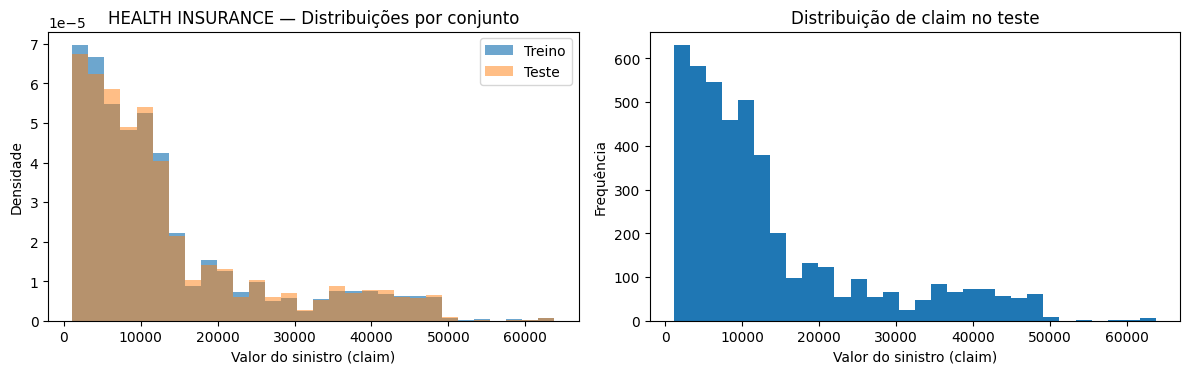

In [9]:
bins = np.histogram_bin_edges(y, bins=30)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=bins, density=True, alpha=0.65, label='Treino')
axes[0].hist(y_test, bins=bins, density=True, alpha=0.5, label='Teste')
axes[0].set_title('HEALTH INSURANCE — Distribuições por conjunto')
axes[0].set_ylabel('Densidade')
axes[0].legend()
axes[1].hist(y_test, bins=bins)
axes[1].set_title('Distribuição de claim no teste')
axes[1].set_ylabel('Frequência')
for ax in axes:
    ax.set_xlabel('Valor do sinistro (claim)')
fig.tight_layout()
plt.show()

## Referência pela média do treinamento

O modelo de referência prevê a média de `claim` do treinamento para todas as observações. Ele permite comparar a regressão com uma previsão constante, mas não corresponde ao pior resultado possível: modelos podem apresentar erros maiores e R² mais negativos.

In [10]:
mean_pred = np.full(len(y_test), y_train.mean(), dtype=float)
display(pd.DataFrame({'claim': y_test, 'previsao_media': mean_pred}).head())

def metricas(real, previsto):
    return {'R2': r2_score(real, previsto),
            'RMSE': rmse_score(real, previsto),
            'MAE': mean_absolute_error(real, previsto)}

metricas_media = metricas(y_test, mean_pred)
display(pd.Series(metricas_media, name='Referência pela média — teste'))
print('RMSE por cálculo direto:', np.sqrt(np.mean((y_test.to_numpy() - mean_pred)**2)))
print('MAE por cálculo direto:', np.mean(np.abs(y_test.to_numpy() - mean_pred)))

,claim,previsao_media
4,1731.7,13351.290529
5,6474.0,13351.290529
6,1705.6,13351.290529
7,1534.3,13351.290529
12,1837.2,13351.290529


,Referência pela média — teste
R2,-0.000192
RMSE,12146.046284
MAE,9139.050583


RMSE por cálculo direto: 12146.046284062535
MAE por cálculo direto: 9139.050583116188


## Avaliação da regressão no treinamento e no teste

RMSE e MAE são expressos na unidade monetária registrada em `claim`, que não está especificada na documentação consultada. Valores menores indicam menor erro. O R² compara o erro quadrático com a variação da resposta e pode ser negativo. O desempenho no treino não substitui a avaliação em dados separados.

In [11]:
pred_train = lr.predict(X_train)
lr_pred = lr.predict(X_test)
resultados = pd.DataFrame([
    {'avaliacao': 'Média do treino — teste', **metricas_media},
    {'avaliacao': 'Regressão — treino', **metricas(y_train, pred_train)},
    {'avaliacao': 'Regressão — teste', **metricas(y_test, lr_pred)}
]).set_index('avaliacao')
display(resultados)

,R2,RMSE,MAE
avaliacao,,,
Média do treino — teste,-0.000192,12146.046284,9139.050583
Regressão — treino,0.771443,5808.028919,3781.641084
Regressão — teste,0.754392,6018.863496,3967.544566


## Previsão de uma observação

O exemplo com vetor numérico fixo do professor é substituído por uma linha da HEALTH INSURANCE com nomes de colunas. Assim, a pipeline aplica as mesmas transformações e preserva a correspondência entre valores e preditoras.

In [12]:
exemplo = X_train.iloc[[1]].copy()
display(exemplo)
print('Valor observado:', y_train.loc[exemplo.index[0]])
print('Previsão pela linha:', lr.predict(exemplo)[0])
print('Mesma previsão no vetor de treino:', pred_train[1])
assert np.isclose(lr.predict(exemplo)[0], pred_train[1])

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78.0,1,1,Engineer


Valor observado: 9567.0
Previsão pela linha: 9663.045715248683
Mesma previsão no vetor de treino: 9663.045715248685


## Resíduos

Definimos resíduo como valor observado menos previsto. Mantemos o histograma de resíduos do treinamento do professor e acrescentamos diagnósticos no teste. Esses gráficos ajudam a identificar padrões de erro, sem comprovar por si só todas as hipóteses da regressão. Não serão utilizados para ajustar decisões ao teste externo.

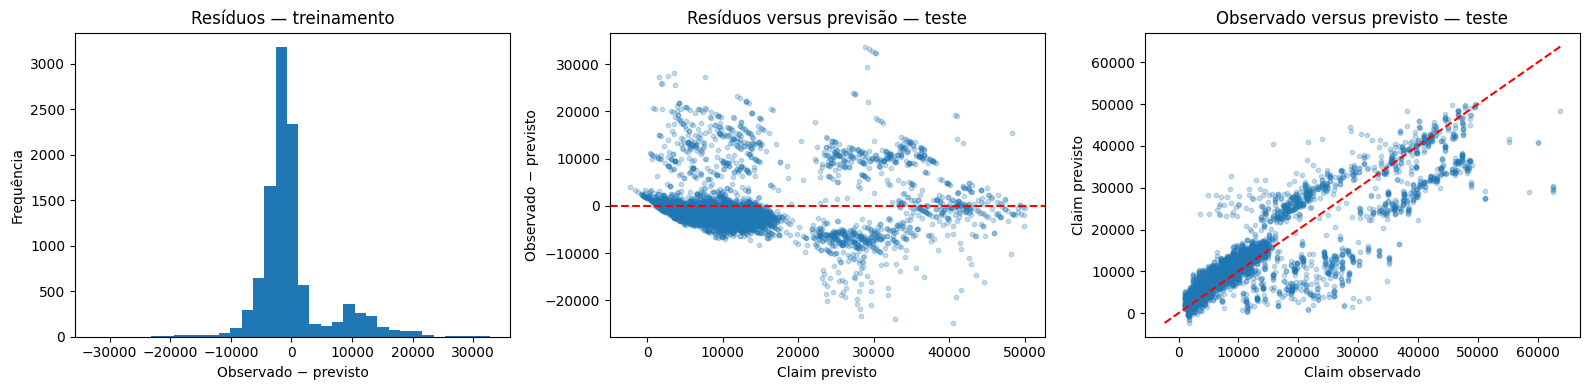

Previsões negativas no teste: 23
As previsões são mantidas sem truncamento para avaliar o modelo ajustado.


In [13]:
residuos_train = y_train.to_numpy() - pred_train
residuos_test = y_test.to_numpy() - lr_pred
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(residuos_train, bins=35)
axes[0].set_title('Resíduos — treinamento')
axes[0].set_xlabel('Observado − previsto')
axes[0].set_ylabel('Frequência')
axes[1].scatter(lr_pred, residuos_test, alpha=0.25, s=10)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('Resíduos versus previsão — teste')
axes[1].set_xlabel('Claim previsto')
axes[1].set_ylabel('Observado − previsto')
axes[2].scatter(y_test, lr_pred, alpha=0.25, s=10)
limites = [min(y_test.min(), lr_pred.min()), max(y_test.max(), lr_pred.max())]
axes[2].plot(limites, limites, color='red', linestyle='--')
axes[2].set_title('Observado versus previsto — teste')
axes[2].set_xlabel('Claim observado')
axes[2].set_ylabel('Claim previsto')
fig.tight_layout()
plt.show()
print('Previsões negativas no teste:', int((lr_pred < 0).sum()))
print('As previsões são mantidas sem truncamento para avaliar o modelo ajustado.')

## Validação cruzada com 10 folds

A validação utiliza somente o conjunto de treinamento externo. Para manter linhas idênticas juntas, usamos `GroupKFold(n_splits=10)` em lugar do KFold comum do professor. A pipeline completa é ajustada novamente em cada treino interno, incluindo as medianas, categorias e escalas. Os tamanhos dos folds podem variar devido aos grupos.

O objeto `cv` é compartilhado entre `cross_validate` e a demonstração manual, permitindo conferir se as duas formas produzem resultados equivalentes.

In [14]:
cv = GroupKFold(n_splits=10)
assert grupos_train.nunique() >= 10
for fold, (idx_treino, idx_val) in enumerate(cv.split(X_train, y_train, grupos_train), 1):
    assert set(grupos_train.iloc[idx_treino]).isdisjoint(set(grupos_train.iloc[idx_val]))
    print(f'Fold {fold}: treino {len(idx_treino)}, validação {len(idx_val)}')

cv_scores = cross_validate(
    cria_modelo(), X_train, y_train,
    groups=grupos_train, cv=cv,
    scoring=('r2', 'neg_root_mean_squared_error', 'neg_mean_absolute_error'),
    return_estimator=True, error_score='raise'
)
cv_resultados = pd.DataFrame({
    'fold': np.arange(1, 11),
    'R2': cv_scores['test_r2'],
    'RMSE': -cv_scores['test_neg_root_mean_squared_error'],
    'MAE': -cv_scores['test_neg_mean_absolute_error']
})
display(cv_resultados)
display(cv_resultados[['R2', 'RMSE', 'MAE']].agg(['mean', 'std']))

Fold 1: treino 9474, validação 1053
Fold 2: treino 9474, validação 1053
Fold 3: treino 9474, validação 1053
Fold 4: treino 9474, validação 1053
Fold 5: treino 9474, validação 1053
Fold 6: treino 9474, validação 1053
Fold 7: treino 9474, validação 1053
Fold 8: treino 9475, validação 1052
Fold 9: treino 9475, validação 1052
Fold 10: treino 9475, validação 1052


,fold,R2,RMSE,MAE
0,1,0.738543,6155.752143,4032.691385
1,2,0.777178,5656.743144,3667.038685
2,3,0.754280,5951.145942,3875.463368
3,4,0.772314,5565.399600,3624.224617
4,5,0.763433,6115.830146,3928.549561
5,6,0.707347,6412.500733,4107.886920
6,7,0.767041,5942.138152,3921.177415
7,8,0.783614,5748.940127,3836.413363
8,9,0.794020,5684.481523,3708.759564
9,10,0.774166,5754.528089,3776.696379


,R2,RMSE,MAE
mean,0.763194,5898.74596,3847.890126
std,0.024916,266.78858,156.942373


## Demonstração manual da validação

Reproduzimos o laço de treinamento e validação do professor, agora com grupos e uma pipeline nova em cada fold. Esta repetição tem finalidade didática e de conferência; não constitui uma segunda seleção de modelo.

In [15]:
rmse, r2, mae = [], [], []
for train_idx, val_idx in cv.split(X_train, y_train, grupos_train):
    X_train_ = X_train.iloc[train_idx]
    y_train_ = y_train.iloc[train_idx]
    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]
    lr_cv = cria_modelo()
    lr_cv.fit(X_train_, y_train_)
    pred_val = lr_cv.predict(X_val)
    rmse.append(rmse_score(y_val, pred_val))
    r2.append(r2_score(y_val, pred_val))
    mae.append(mean_absolute_error(y_val, pred_val))

assert np.allclose(rmse, cv_resultados['RMSE'])
assert np.allclose(r2, cv_resultados['R2'])
assert np.allclose(mae, cv_resultados['MAE'])
print('Resultados manuais e cross_validate equivalentes.')
print('RMSE:', rmse, '\nMédia:', np.mean(rmse))
print('R2:', r2, '\nMédia:', np.mean(r2))
print('MAE:', mae, '\nMédia:', np.mean(mae))

Resultados manuais e cross_validate equivalentes.
RMSE: [6155.752142829543, 5656.743144171377, 5951.145941943573, 5565.399600379859, 6115.830145985618, 6412.5007332681735, 5942.138151593545, 5748.940127107935, 5684.481522875208, 5754.528089105489] 
Média: 5898.745959926031
R2: [0.7385432893993962, 0.7771777107151004, 0.7542802039004909, 0.7723140771366198, 0.7634332429893607, 0.7073473285505061, 0.7670405938855025, 0.7836138515456325, 0.7940203230541548, 0.7741656235678073] 
Média: 0.763193624474457
MAE: [4032.69138453555, 3667.038685171545, 3875.4633675246173, 3624.224617278197, 3928.5495614653128, 4107.886919606939, 3921.177414618057, 3836.413362583388, 3708.7595640039995, 3776.6963785534017] 
Média: 3847.8901255341016


## Distribuição do RMSE de validação

Mantemos boxplot, violinplot e histograma do professor em uma única figura. Com apenas dez folds, os gráficos descrevem a dispersão observada; não representam intervalos de confiança.

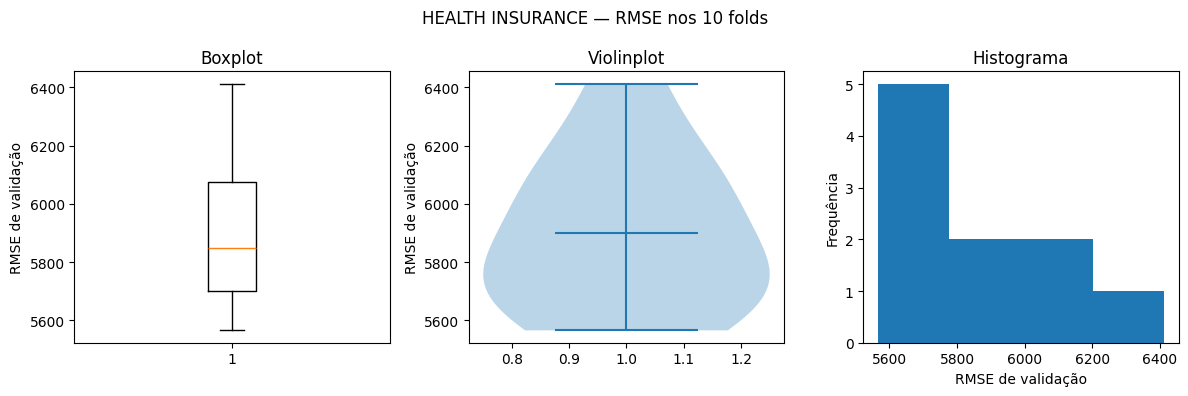

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].boxplot(rmse)
axes[0].set_title('Boxplot')
axes[1].violinplot(rmse, showmeans=True)
axes[1].set_title('Violinplot')
axes[2].hist(rmse, bins=4)
axes[2].set_title('Histograma')
axes[0].set_ylabel('RMSE de validação')
axes[1].set_ylabel('RMSE de validação')
axes[2].set_xlabel('RMSE de validação')
axes[2].set_ylabel('Frequência')
fig.suptitle('HEALTH INSURANCE — RMSE nos 10 folds')
fig.tight_layout()
plt.show()

## Modelos dos folds no teste externo — demonstração do professor

O notebook original também aplica cada modelo dos folds ao teste externo. Mantemos essa demonstração em uma célula opcional desativada. Seus resultados não deverão ser usados para escolher o melhor fold, calibrar transformações ou ajustar o modelo. A avaliação principal de teste é a regressão treinada com todo o conjunto de treinamento externo.

Caso os modelos sejam posteriormente escolhidos ou ajustados, as decisões deverão ocorrer usando apenas a validação de treinamento e uma nova avaliação final independente será necessária.

In [17]:
executar_demonstracao_teste_folds = False
if executar_demonstracao_teste_folds:
    teste_folds = pd.DataFrame([
        {'fold': fold, **metricas(y_test, modelo.predict(X_test))}
        for fold, modelo in enumerate(cv_scores['estimator'], 1)
    ])
    display(teste_folds)
else:
    print('Demonstração opcional desativada. Resultados externos não serão usados para escolher folds.')

Demonstração opcional desativada. Resultados externos não serão usados para escolher folds.


## Tabela de previsões

Criamos uma tabela separada, sem acrescentar previsões diretamente a `y_test`. Isso evita alterar a variável resposta utilizada nas métricas.

In [18]:
previsoes_teste = pd.DataFrame({
    'claim_observado': y_test,
    'claim_previsto': lr_pred,
    'previsao_media_treino': mean_pred,
    'residuo': y_test.to_numpy() - lr_pred
}, index=y_test.index)
display(previsoes_teste)
assert list(X.columns) == list(X_train.columns) == list(X_test.columns)
assert 'claim' not in X.columns
assert 'pred' not in y_test.to_frame().columns
print('Demonstrações de regressão linear concluídas.')

,claim_observado,claim_previsto,previsao_media_treino,residuo
4,1731.7,2592.329893,13351.290529,-860.629893
5,6474.0,7757.156169,13351.290529,-1283.156169
6,1705.6,600.887149,13351.290529,1104.712851
7,1534.3,4067.845022,13351.290529,-2533.545022
12,1837.2,555.728202,13351.290529,1281.471798
...,...,...,...,...
14987,8083.9,12882.099597,13351.290529,-4798.199597
14988,19214.1,11969.508988,13351.290529,7244.591012
14992,10494.0,11586.067611,13351.290529,-1092.067611
14993,11454.0,12880.825138,13351.290529,-1426.825138


Demonstrações de regressão linear concluídas.


## Correspondência com o notebook do professor

| Células originais (posição iniciando em zero) | Adaptação |
|---|---|
| 0–5 | Importações, carregamento HEALTH INSURANCE, `claim` e inspeção |
| 6–7 | Indicadores e categoria de referência dentro da pipeline |
| 8–9 | Divisão externa 70/30 por grupos, semente 1, tamanhos efetivos |
| 10–17 | Ajuste, coeficientes, intercepto e média do treino; médias de teste não utilizadas para ajustar o modelo |
| 18–19 | Distribuições do treino e teste em painel |
| 20–24 | Referência pela média, R², RMSE, MAE e cálculos diretos |
| 25–28 | Métricas treino/teste e previsão de uma linha da HEALTH INSURANCE |
| 29 | Resíduos de treino, com diagnósticos adicionais no teste |
| 30–33 | Validação de 10 folds com grupos e pipeline completa |
| 34 | Modelos dos folds no teste: demonstração opcional desativada |
| 35 | Laço manual equivalente a cross_validate |
| 36–39 | Boxplot, violinplot e histograma numa figura |
| 40 | Tabela de previsões separada, preservando a resposta |
| 41 | Célula vazia não reproduzida |

Repetições de intercepto, coeficientes e ajuste do mesmo modelo foram reunidas. Essas mudanças preservam os tópicos didáticos, adaptando a execução aos dados incompletos e às repetições da HEALTH INSURANCE.

## Referências e reprodução

- Fonte da base: Suresh Gupta, Health Insurance Data Set, Kaggle: https://www.kaggle.com/datasets/sureshgupta/health-insurance-data-set
- Cópia utilizada: arquivo `data/healthinsurance.csv` do repositório do trabalho, carregado pela URL no código. Para uma reprodução exata, registrar o commit do arquivo utilizado.
- Kühlem et al. (2025): https://doi.org/10.1002/asmb.70029
- Pipelines e prevenção de vazamento: https://scikit-learn.org/stable/common_pitfalls.html
- Particionamento e validação por grupos: https://scikit-learn.org/stable/modules/cross_validation.html

Execute todas as células em ordem, em um ambiente com pandas, numpy, matplotlib e scikit-learn compatível com `OneHotEncoder(sparse_output=False)`. O notebook é entregue sem resultados calculados: a interpretação das métricas será elaborada após a execução. Não se pressupõe ganho de desempenho antes de observar as saídas.